# 언어모델 & 생성모델 정리

### 목차
1. NLP와 언어 모델
2. 통계적 언어 모델 (SLM)
3. 신경망 언어 모델 (NLM)
4. 딥러닝 기반 언어 모델
5. sLM
6. 생성 모델 개념
7. AE, VAE
8. GAN
9. 확산 모델

---

### 1. NLP와 언어 모델

#### 1-1. NLP

- **NLP**
: 사람의 언어를 컴퓨터가 분석, 이해, 생성하게 하는 기술
    - 언어를 숫자로 바꿔서 단어 관계와 문맥 분석

- 자연어 vs 프로그래밍 언어
    - 자연어: 일대다 → 유연, 모호
    - 프로그래밍 언어: 일대일 → 명확, 엄격

- **자연어 특징**
    - 이산적: 기호로 수학적 처리 어려움  → 임베딩
    - 순차적: 순서에 따라 의미가 바뀜 → RNN, Transformer
    - 중의성: 하나의 단어가 여러 가지로 해석됨 → 문맥 전체 파악
    - 희소성: 조합이 너무 많아 학습 어려움 → 확률적 추론 
    - 가변성: 신조어, 줄임말 등 변화 → 데이터 기반 학습

- **활용**: 번역, 감성 분석, 텍스트 분류, 요약, 챗봇

- **NLP 분석 단계**
    1. 형태소 분석: 최소 단위로 쪼개고 품사와 특징 분석
    2. 구문 분석: 문법 구조 파악
    3. 의미 분석: 문맥에 맞는 뜻 파악 
    4. 담화 분석: 문장 사이 관계 파악

#### 1-2. 언어 모델

- **언어 모델**
: 다음 단어 확률을 예측하고 문장이 자연스러운지 판단하는 모델
    - 확률 높은 문장 = 자연스러운 문장
- 종류: **SLM** (통계 기반), **NLM** (신경망 기반)

---

### 2. 통계적 언어 모델 (SLM)

#### 2-1. SLM 개념

- **분포 가설**
: 비슷한 문맥에 나오는 단어는 유사한 의미
    - 임베딩의 이론적 기반이 됨

- **조건부 확률**: 앞 문맥이 주어졌을 때 다음 단어가 등장할 확률

- **카운트 기반 확률**: 등장 횟수로 확률 계산
    - 빈도 높을수록 높은 확률

- 한계: 희소 문제
    - 데이터에 없는 조합은 확률 0

#### 2-2. N-gram

- 배경: 이전 단어들의 데이터 희소성↑, 계산의 복잡성↑

- **N-gram**
: 직전 N-1개 단어만 보고 다음 단어를 예측하는 모델
- 문맥 범위를 N-1개로 제한해 SLM을 단순화한 것
- 한계
    - N↑ → 조합 증가 → 희소 문제 심해짐
    - 멀리 떨어진 단어 관계 파악 어려움

#### 2-3. Perplexity (PPL)

- **PPL**
: 모델이 다음 단어 예측에서 얼마나 혼란스러워 하는지 나타내는 수치
    - 낮을수록 좋은 모델
- 희소한 문장일수록 PPL↑
- 예측 쉬운 단어가 추가되면 PPL↓ 가능 (항상은 아님)
- SLM, NLM 둘 다 평가 가능 → 보통 NLM이 더 낮음

---

### 3. 신경망 언어 모델 (NLM)

- 등장 배경: SLM 한계 보완, 신경망으로 의미와 문맥을 학습
- **임베딩**
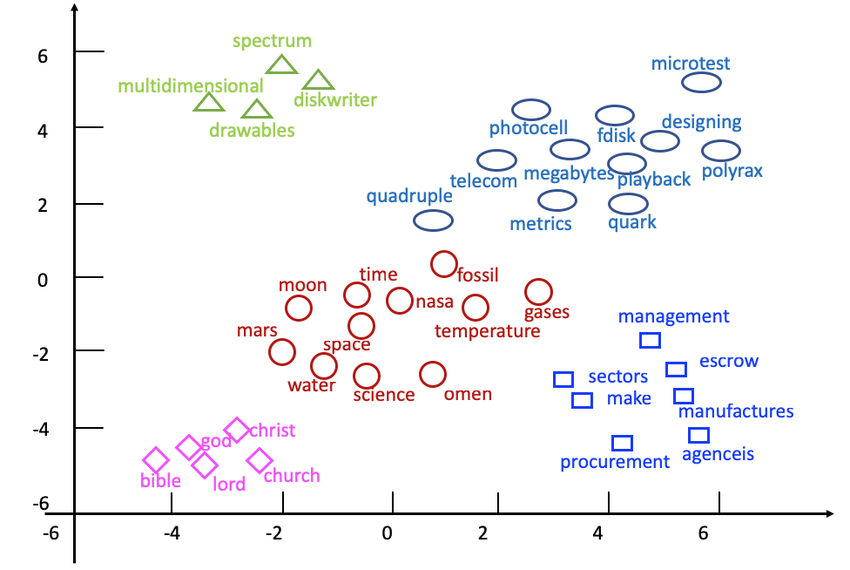
    - 단어를 벡터 공간의 한 점으로 표현
    - 의미가 비슷하면 가까이 위치
    - 학습 데이터에 없는 표현도 일반화 가능

| 구분 | SLM | NLM |
|---|---|---|
| 학습 | 빈도, 확률 계산 | 신경망 가중치 학습 |
| 단어 표현 | 개별 기호 | 연속 벡터 |
| 의미 관계 | 반영 어려움 | 임베딩으로 학습 |
| 희소 문제 | 취약 | 완화 |
| 문맥 | N-gram은 N-1개만 | 구조에 따라 긴 문맥 가능 |
| 계산 비용 | 낮음 | 높음 |

---

### 4. 딥러닝 기반 언어 모델

#### 4-1. Transformer

- **RNN, LSTM 한계**
    - 장기 의존성: 앞쪽 정보가 점점 희미해짐
    - 기울기 소실: 앞쪽까지 학습 신호가 잘 전달 안 됨
    - 순차 처리: 병렬화 안 돼서 느림
- **Transformer**
    - Self-Attention으로 장거리 문맥 학습
    - 병렬 처리 + 위치 인코딩
    - 이후 BERT, GPT의 기반
- **구조**
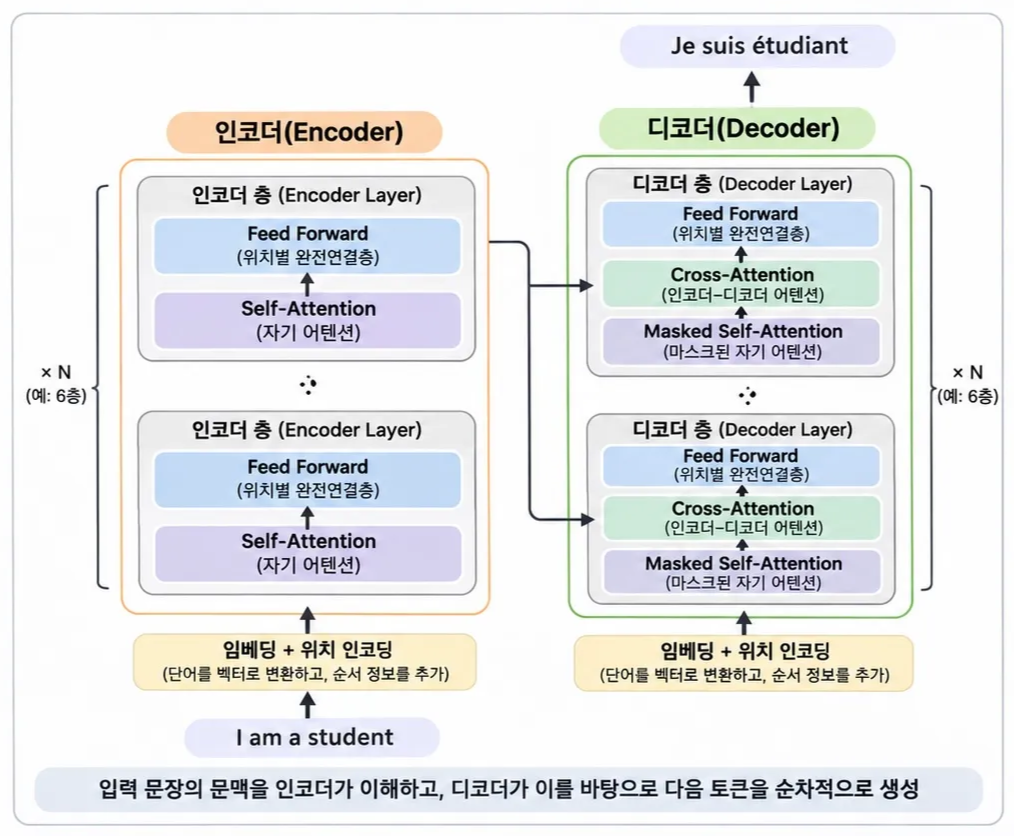
    - 입력: 토큰화 → 임베딩 + 위치 인코딩
    - 인코더: Self-Attention + FFN, 여러 층
    - 디코더: Masked Self-Attention + Cross-Attention + FFN, 한 단어씩 생성

#### 4-2. BERT

- **BERT**
: Transformer 인코더 기반, 양방향 문맥으로 언어를 이해하는 모델
    - B: Bidirectional / ER: Encoder Representations / T: Transformers
- 특징
    - 양방향: 앞뒤 단어 모두 참고
    - 인코더만 사용
    - 사전학습 + 파인튜닝
- 학습 방법: 토큰화 (`[CLS]`, `[SEP]` 추가) → 임베딩 (토큰 + 위치 + 문장 구분) → 인코더 층 → 분류, 감성 분석, 질의 응답 등
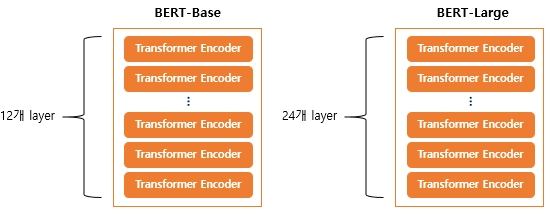
- **사전 학습**: 레이블 없이 텍스트 자체로 학습
    - **MLM** (빈칸 채우기)  
    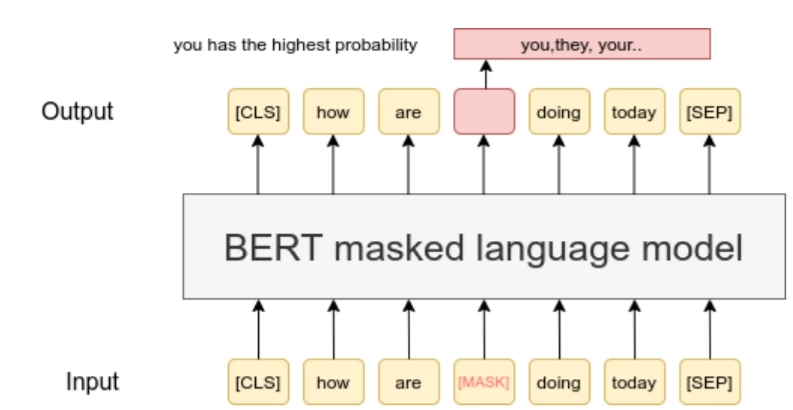
        - 일부 토큰을 `[MASK]`로 가리고 앞뒤 문맥으로 원래 단어 예측
        - 효과: 양방향 이해, 문맥에 따라 달라지는 뜻 학습
    - **NSP** (다음 문장 예측)
    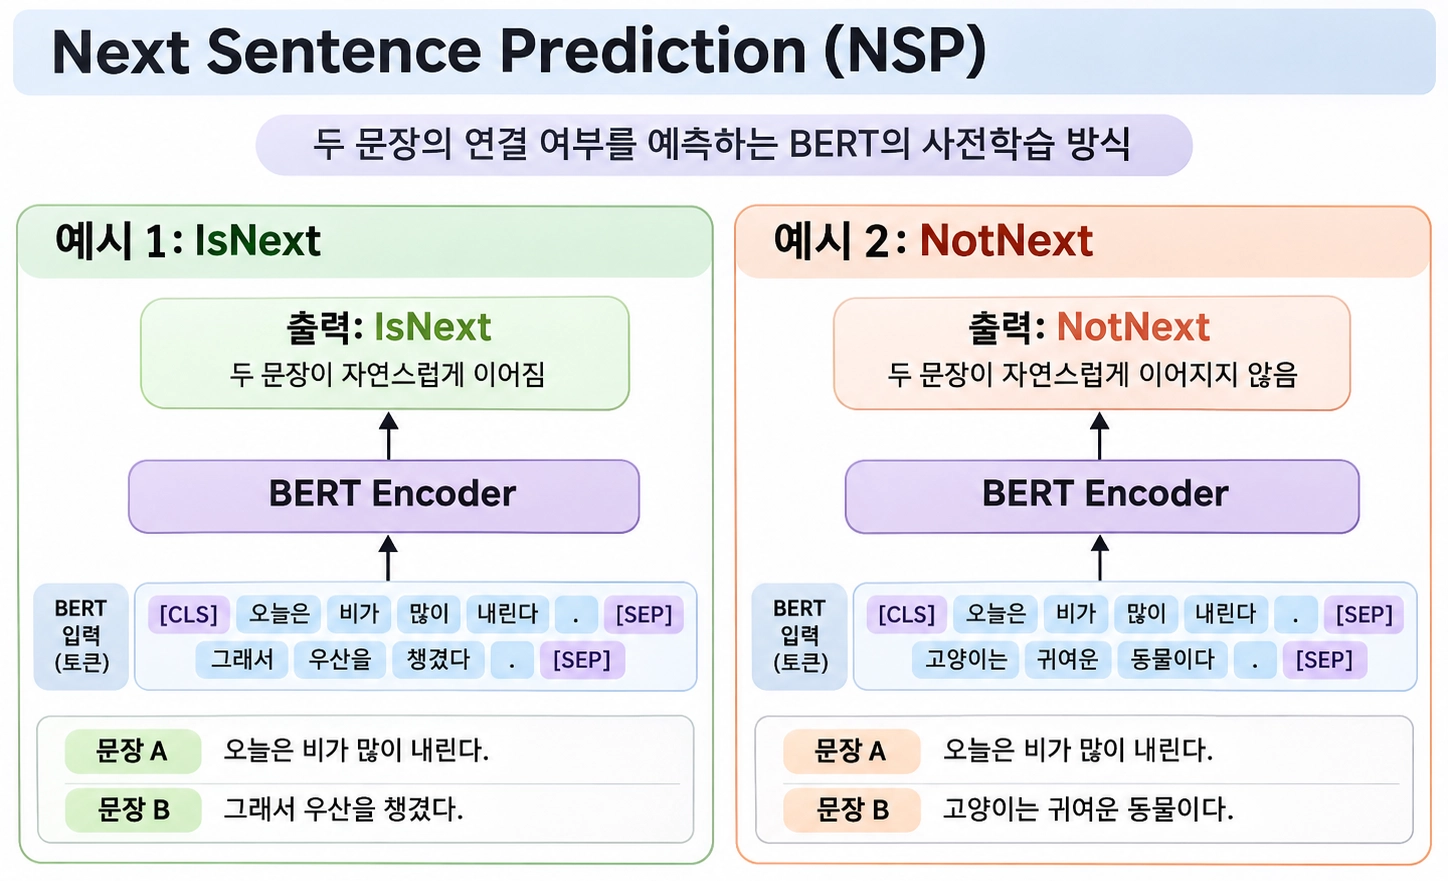
        - B가 A 바로 다음 문장인지 판단 → IsNext / NotNext
        - 효과: 문장 간 관계 학습
- **BERT 이후 모델**
    - RoBERTa: NSP 제거, Dynamic Masking
    - ALBERT: 임베딩 분해 + 계층간 파라미터 공유로 경량화, NSP → SOP

#### 4-3. GPT

- **GPT**
: Transformer 디코더 기반, 이전 단어로 다음 단어를 생성하는 모델
    - Cross-Attention x (인코더 없음)
    - Masked Self-Attention이 핵심
    - FFN
- **GPT-3**: 파인튜닝 없이 프롬프트만으로 작업 수행 (In-Context Learning)
    - Zero-shot: 지시만 / One-shot: 예시 1개 / Few-shot: 예시 여러 개

| 구분 | BERT | GPT |
|---|---|---|
| 구조 | 인코더 | 디코더 |
| 방향 | 양방향 | 단방향 (자기회귀) |
| 학습 | MLM, NSP | 다음 토큰 예측 |
| 목적 | 이해 | 생성 |
| 대표 작업 | 감성 분석, 분류, 개체명 인식 | 챗봇, 생성, 번역, 요약 |

#### 4-4. LLM

- **LLM**
: 대규모 데이터 + 대규모 신경망으로 언어를 이해하고 생성하는 모델
    - 대부분 Transformer 기반 (GPT, LLaMA, Claude, Gemini)
- **학습**
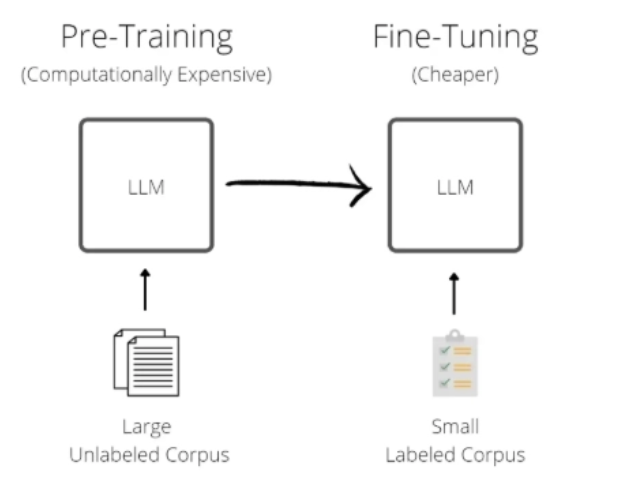
    - 사전 학습: 다음 토큰 예측을 반복하며 언어 구조 학습
    - 파인튜닝: 특정 작업 데이터로 추가 학습
    - 예측과 정답의 차이를 줄이도록 가중치 업데이트
- **예측**: 토큰, 벡터화 → Attention으로 문맥 분석 → 다음 토큰 확률 예측 → 응답 생성
- **한계**
    - 환각 현상: 확률 기반이라 사실 보장 x → RAG 등으로 완화
    - 비용: 학습, 업데이트 비쌈, 최신 정보 자동 반영 x

#### 4-5. RAG

- **RAG**
: 외부 검색 + LLM 생성 결합 → 정확성, 최신성 향상
    - 배경: LLM은 학습 이후 정보를 모름
- 구조
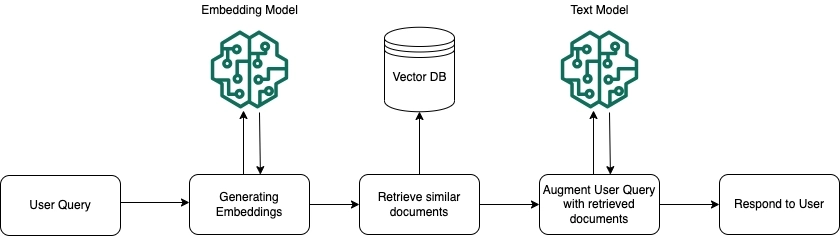
    1. 질의 인코더: 질문 → 벡터
    2. 지식 검색기: Vector DB에서 유사한 문서 검색
    3. 생성기: 질문 + 검색 문서 → LLM이 답변 생성
- 장점
    - 재학습 없이 최신 정보 반영
    - 근거 기반 답변 → 환각 완화

- **CAG (Credibility-aware Generation)**
: 문서의 신뢰도까지 판단해서 답변하는 기법
    - RAG 한계: 관련성만 보고 오래되거나 부정확한 문서를 쓸 수 있음
    - CAG: 출처 신뢰성과 최신성까지 평가 → 믿을 만한 정보 우선
    - 흐름: 질문 → 검색 → 신뢰도 평가 → 선별 → 답변

#### 4-6. LangChain

- **LangChain**
: LLM을 외부 데이터, API, 도구와 연결해 앱을 쉽게 만드는 오픈소스 프레임워크
    - 배경: 구현 복잡, 외부 연동 어려움, 유지보수 어려움
- 특징
    - 추상화: 복잡한 기능을 간단한 인터페이스로
    - 표준화: 모델을 바꿔도 연결 부분만 수정해 활용
    - 체이닝: 작업을 순서대로 연결 (입력 → 번역 → 요약 → 출력)

- **LangGraph**
: 노드, 엣지로 분기, 반복이 가능한 워크플로를 만드는 프레임워크
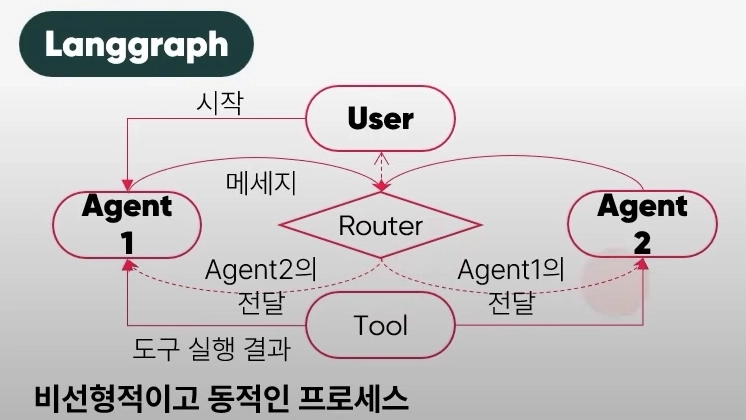
    - 체이닝은 선형 → 조건 분기, 반복 실행, 상태 관리 필요할 때 사용
    - 노드: 작업 단위 (LLM, Agent, Tool)
    - 엣지: 노드 간 연결, 다음 경로 결정
    - 상태: 노드끼리 공유하는 정보 (결과, 대화 문맥)
    - 흐름: User → Router → Agent ↔ Tool → 반복 → 응답

- **LangSmith**
: LLM 앱의 실행 추적, 평가, 모니터링 플랫폼
    - 디버깅, 추적: 입출력, 실행 과정 추적, 오류 원인 확인
    - 테스트, 평가: 변경 전후 결과 비교
    - 모니터링: 응답 시간, 오류율, 비용
    - 프롬프트 허브: 프롬프트 저장, 공유, 버전 관리

- **외부 API**
    - 내부 지식으로 안 되는 질문은 API 연동으로 해결
    - OpenAI 키 발급: 가입 → 결제 등록 → 키 생성 → 보관
    - 주의: 전체 키는 생성할 때 한 번만 보임, 타인과 공유 금지

---

### 5. sLM (small Language Model)

- **sLM**
: LLM보다 작은 언어 모델
    - sLM: 수백만~수십억 파라미터 / LLM: 수십억~수천억+
    - 파라미터: 학습으로 얻는 모델 내부 값
    - 자원 적게 씀 → 모바일, 오프라인 추론 가능

| 구분 | LLM | sLM |
|---|---|---|
| 크기 | 큼 | 작음 |
| 성능 | 복잡한 추론에 강함 | 특정, 단순한 작업에 효율적 |
| 비용 | 높음 | 낮음 |
| 속도 | 상대적으로 느림 | 빠름 |
| 환경 | 고성능 서버 | 서버, 스마트폰, 노트북 |

#### 5-1. 모델 압축

1. **가지치기 (Pruning)**: 중요도 낮은 연결, 뉴런 제거
2. **양자화 (Quantization)**: 숫자 정밀도 낮추기
    - FP32 → FP16 / INT8
    - 메모리↓, 속도↑, 대신 정밀도 손실
3. **저차원 분해 (Low-Rank Factorization)**: 큰 행렬 ≈ 작은 행렬 두 개의 곱
4. **지식 증류 (Knowledge Distillation)**: 큰 모델(Teacher) → 작은 모델(Student)에 지식 전달

- 예시: DistilBERT (BERT 증류), Gemma (Google), GPT-4o mini (OpenAI), Llama (Meta), Ministral (Mistral, 온디바이스), Phi (Microsoft)
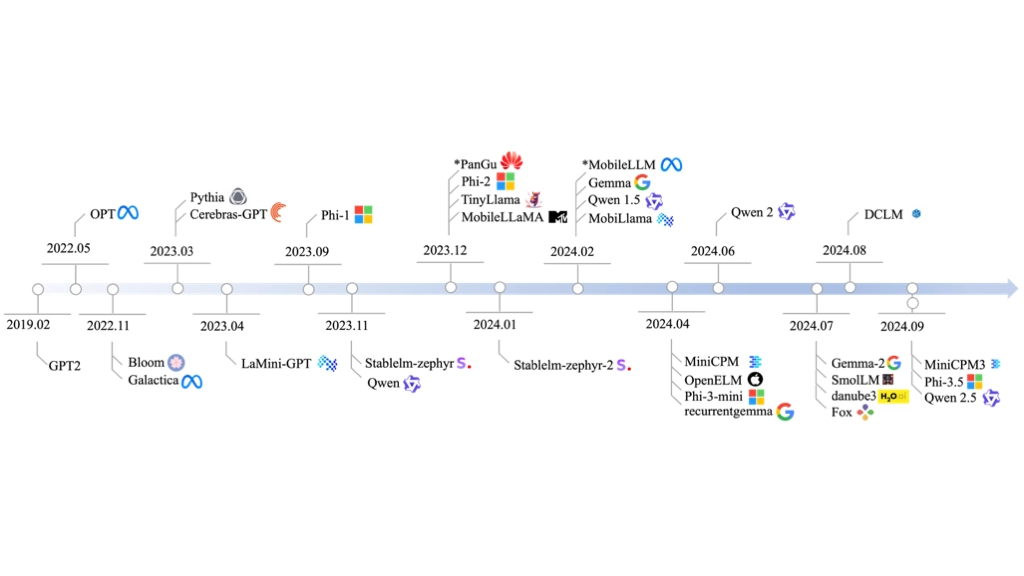

#### 5-2. 장단점

- 장점
    - 성능: 빠름, 제한된 환경에서도 실행, 외부 전송 없이 보안 유지
    - 비용: 운영비, 전력, 하드웨어 비용↓
- 한계
    - 편향: 데이터 편향이 그대로 반영
    - 일반화, 복잡한 추론 약함
    - 환각

#### 5-3. 결합 추론 (Hybrid Inference)

- 쉬운 작업은 sLM, 어려운 작업은 LLM
- 성능과 비용의 균형

---

### 6. 생성 모델 개념

#### 6-1. 분류 모델 vs 생성 모델

- **생성 모델**
: 학습 데이터의 분포를 학습해 비슷한 새 데이터를 만드는 모델

| 구분 | 분류 모델 | 생성 모델 |
|---|---|---|
| 목표 | P(Y\|X): X가 어떤 Y인지 | P(X): X가 나올 분포 |
| 학습 | 특징과 레이블의 관계 | 특징과 확률분포 |
| 출력 | 범주, 확률 | 새 이미지, 텍스트, 음성 |
| 한계 | 이상한 입력도 기존 라벨로 분류, 생성 x | 부자연스러운 결과, 품질 평가 어려움 |

#### 6-2. 생성 모델의 분류

- 기준: **확률밀도를 직접 계산할 수 있는가?**

- **명시적 확률밀도 모델**
: P(X)를 수치로 계산하거나 근사하는 모델
    - 확률밀도 = 학습 분포에서 얼마나 그럴듯한지 나타내는 값
    - **Tractable**: 정확히 계산 가능
        - NADE, MADE, PixelRNN/CNN, Change of Variables
    - **Approximate**: 계산 어려워 근사
        - VAE: 변분 추론 사용
        - Boltzmann Machine: 마르코프 연쇄 사용

- **암시적 확률밀도 모델**
: P(X) 계산 x, 새 데이터 샘플링에 집중
    - **직접 샘플링**: 노이즈 → 모델 한 번 통과 → 생성 (GAN)
    - **간접/반복 샘플링**: 상태 변화를 여러 번 반복해서 생성 (GSN)

---

### 7. AE, VAE

#### 7-1. AE (Auto Encoder)

- **AE**
: 입력을 압축했다가 복원하면서 핵심 특징을 학습하는 모델
    - 레이블 x, 입력 자체가 정답
    - 활용: 데이터 압축, 노이즈 제거, 이상 탐지
- **기존 인코더-디코더와 차이**
    - 기존: 다른 결과를 생성 (한국어 → 영어)
    - AE: 원래 입력을 복원 
- **구조**
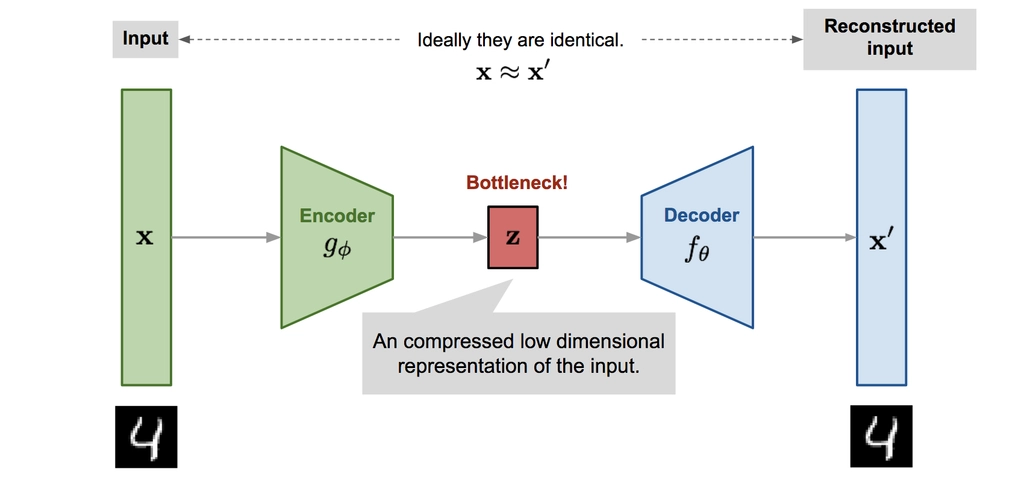
    1. 인코더: x → 잠재 벡터 z로 압축
    2. 병목: 좁은 공간에 핵심 정보만 담음
    3. 디코더: z → x' 복원
- 왜 압축했다 복원?
    - 압축 안 하면 그냥 복사
    - 복원해서 압축 정보만으로 원본을 만들 수 있는지 확인
    - 복원 오차를 줄이며 학습 → 데이터의 핵심 구조 학습

#### 7-2. VAE (Variational Auto Encoder)

- **등장 배경**: AE의 잠재공간은 불규칙
- **VAE**
: 특징을 확률분포로 학습해서 샘플링으로 새 데이터를 생성하는 모델
- **학습 목표**
    1. 복원 오차↓: 원본과 비슷하게 복원
    2. KL 발산↓: 잠재분포를 표준정규분포에 가깝게
        - KL 발산: 두 분포가 얼마나 다른지, 같으면 0
- **AE vs VAE**
    - AE: 입력을 **점** 하나로 표현 → 잠재공간 불규칙
    - VAE: 입력을 **분포**로 표현 → 잠재공간 연속적, 규칙적 → 사이 공간에서도 샘플링 가능
- 작동 과정
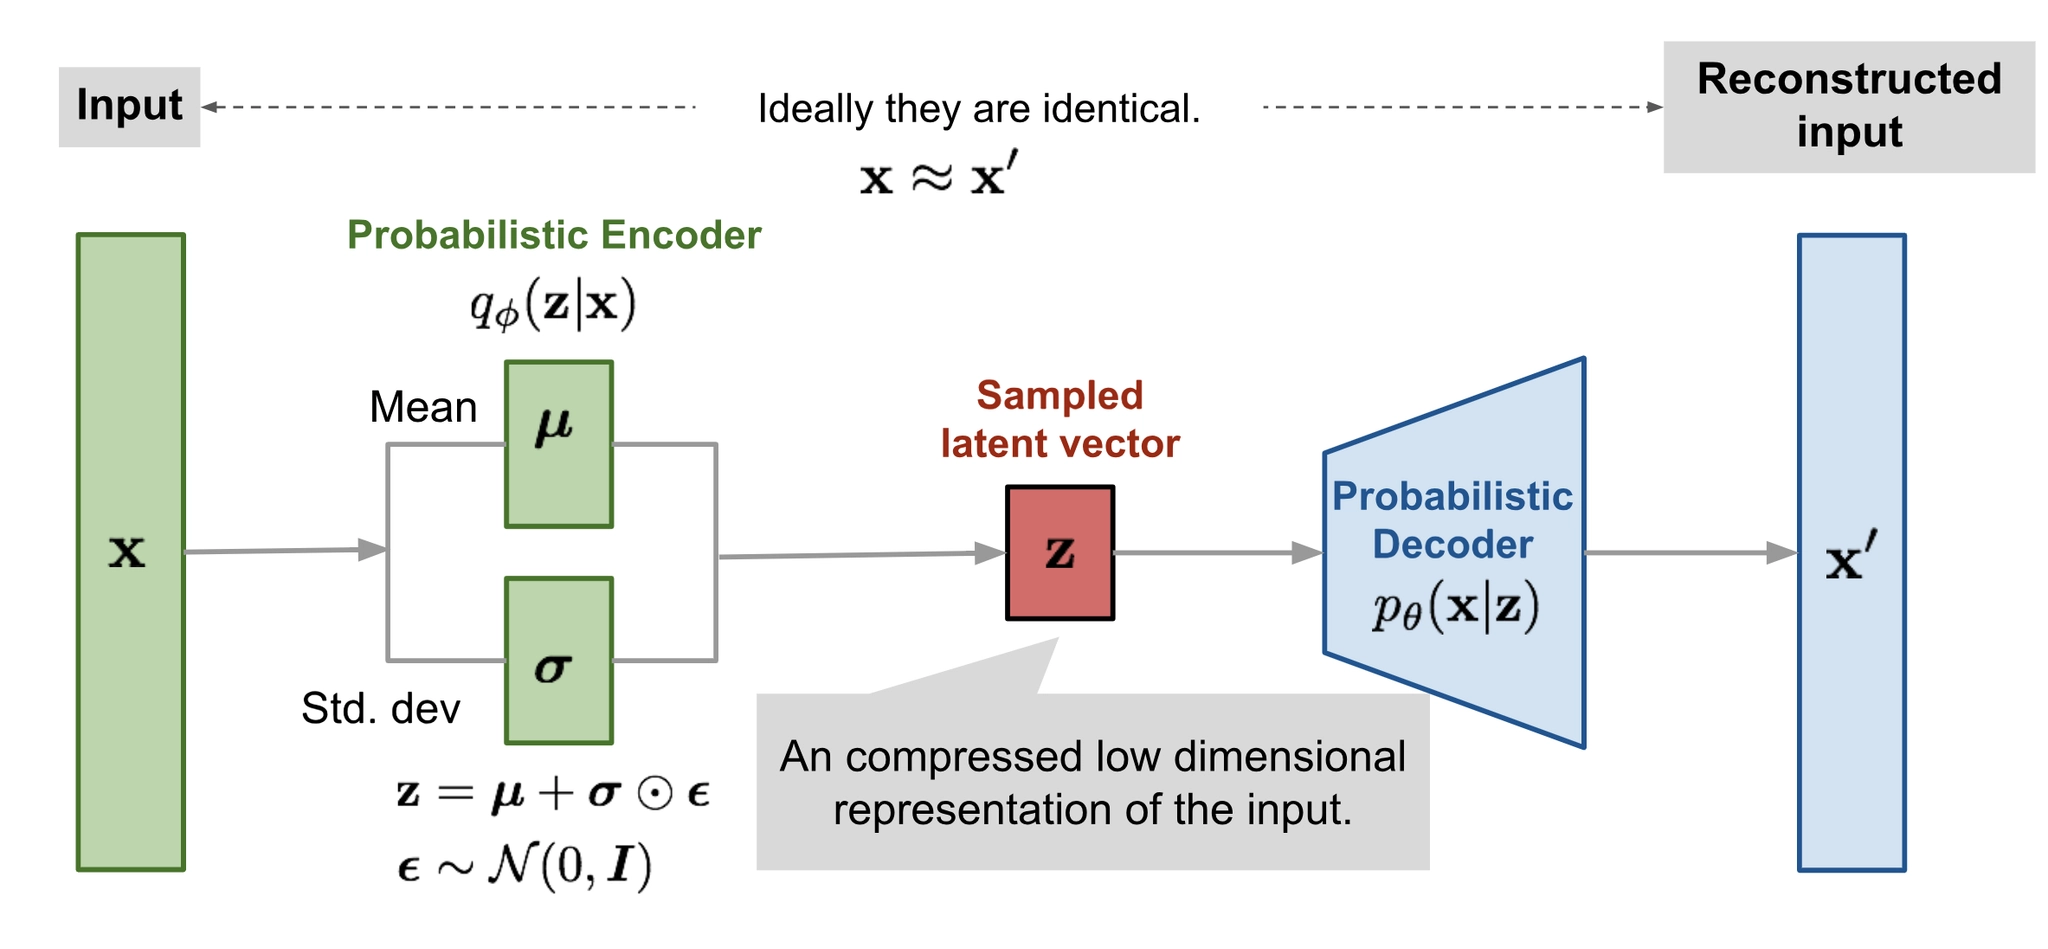
    1. **분포 예측**: 인코더가 μ, σ 예측
    2. **샘플링 + 재파라미터화**
        - 샘플링 무작위성을 ε로 분리해서 기울기 전달
    3. **생성**: 디코더로 x' 생성
        - 학습: x가 x'가 되도록
        - 복원 or 새 데이터 생성

---

### 8. GAN

#### 8-1. GAN 개념

- **GAN**
: 생성자(G)와 판별자(D)가 경쟁하며 진짜 같은 데이터를 만드는 모델
- **G**: 노이즈 → 가짜 데이터, D를 속이도록 학습
- **D**: 진짜/가짜 입력 → 진짜일 확률 예측, 정확히 구별하도록 학습
- **목적**: G가 실제 데이터 분포를 학습 → 학습 후에는 G만 사용
- **활용**: 가상 얼굴 생성, 이미지 복원, 데이터 증강

#### 8-2. GAN 구조

- 노이즈 z → G → 가짜 G(z)
- D 입력: 진짜 x 또는 G(z) → 출력: 0~1

#### 8-3. GAN 장단점

- **장점**
    - 진짜 같은 가짜 데이터 생성
    - 선명함: 세부적인 특징 표현
    - 빠른 생성: 노이즈를 한 번 통과시키면 끝
    - 부드러운 잠재공간: z를 조금씩 바꾸면 이미지도 자연스럽게 변함 (항상은 x)

- **한계**
    - 학습 불안정
    - 훈련 초기 문제: 충분한 학습 신호 받지 못하는 문제
    - 모드 붕괴: 특정 데이터만 반복 생성
    - 평가 지표의 한계: 하나의 지표로는 한계
    - 역매핑 어려움: z로 되돌리는 인코더 x

#### 8-4. GAN 적용 사례

- **Progressive GAN** (NVIDIA): 실존하지 않는 인물 얼굴 생성
- **Deep Video Portraits** (cGAN): 표정, 움직임을 영상에 합성
- **Eye In-Painting** (Facebook, ExGAN): 감은 눈을 뜬 눈으로 복원

---

### 9. 확산 모델 (Diffusion Model)

#### 9-1. 개념

- **확산 모델**
: 노이즈에서 시작해 노이즈를 조금씩 제거하며 이미지를 생성하는 모델
    - 순확산: 이미지에 노이즈 추가
    - 역확산: 노이즈 제거하며 생성
- **목적**: 데이터 분포를 학습해 자연스럽고 다양한 데이터 생성
- **모호성 모델링**: 한 조건에 여러 결과가 가능 → 확률적으로 표현

#### 9-2. 구조

- **순확산 (Forward)**
    - 원본 → 가우시안 노이즈를 조금씩 추가 → 무작위 노이즈
    - 가우시안 노이즈: 정규분포를 따르는 잡음
    - 목적: 노이즈 제거를 학습할 데이터 만들기
- **역확산 (Reverse)**
    - 무작위 노이즈 → Denoising U-Net이 노이즈 예측, 제거 반복 → 새 이미지

#### 9-3. 장단점

- 장점
    - 품질: 단계적으로 생성해서 정교함
    - 안정성: 경쟁 x, 노이즈 예측 MSE → 손실 곡선으로 확인 가능
    - 다양성: 무작위 노이즈에서 시작 → 같은 조건에도 다른 결과
- 단점
    - 느림: 여러 단계 반복 필요
    - 계산 비용: GPU 많이 필요
    - 구조 제약: 속도와 품질이 달라짐